In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("data/raw/ not found above " + str(start))

ROOT = find_project_root()
RAW_DIR = ROOT / "data" / "raw"
PROC_DIR = ROOT / "data" / "processed"

index_names = ["unit", "cycle"]
setting_names = [f"setting_{i}" for i in range(1, 4)]
sensor_names = [f"sensor_{i}" for i in range(1, 22)]
col_names = index_names + setting_names + sensor_names

train = pd.read_csv(RAW_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=col_names)
test = pd.read_csv(RAW_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=col_names)
rul_test = pd.read_csv(RAW_DIR / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])
print(train.shape, test.shape, rul_test.shape)

(20631, 26) (13096, 26) (100, 1)


In [2]:
for name, df in [("train", train), ("test", test)]:
    print(f"--- {name} ---")
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicate rows:", int(df.duplicated().sum()))
    print("duplicate (unit, cycle) pairs:", int(df.duplicated(subset=["unit", "cycle"]).sum()))
    numeric = df.select_dtypes(include=[np.number])
    print("non-finite values (inf/-inf):", int(np.isinf(numeric).sum().sum()))

--- train ---
missing values: 0
duplicate rows: 0
duplicate (unit, cycle) pairs: 0
non-finite values (inf/-inf): 0
--- test ---
missing values: 0
duplicate rows: 0
duplicate (unit, cycle) pairs: 0
non-finite values (inf/-inf): 0


In [3]:
def check_continuity(df, name):
    bad = []
    for u, d in df.groupby("unit"):
        cycles = d["cycle"].to_numpy()
        expected = np.arange(1, len(d) + 1)
        if not np.array_equal(np.sort(cycles), expected):
            bad.append(u)
    print(f"{name}: engines with gaps or wrong start: {bad if bad else 'none'}")
    print(f"{name}: rows sorted by (unit, cycle):",
          df.sort_values(["unit", "cycle"]).index.equals(df.index))

check_continuity(train, "train")
check_continuity(test, "test")

train: engines with gaps or wrong start: none
train: rows sorted by (unit, cycle): True
test: engines with gaps or wrong start: none
test: rows sorted by (unit, cycle): True


In [4]:
feature_cols = setting_names + sensor_names

profile = train[feature_cols].agg(["nunique", "min", "max", "std"]).T
profile["range"] = profile["max"] - profile["min"]
profile = profile.sort_values("nunique")
print(profile.head(12))

constant_cols = profile.index[profile["nunique"] == 1].tolist()
print("\nConstant in train (nunique == 1):", constant_cols)

           nunique        min        max           std    range
sensor_1       1.0   518.6700   518.6700  0.000000e+00   0.0000
setting_3      1.0   100.0000   100.0000  0.000000e+00   0.0000
sensor_5       1.0    14.6200    14.6200  5.329200e-15   0.0000
sensor_10      1.0     1.3000     1.3000  0.000000e+00   0.0000
sensor_18      1.0  2388.0000  2388.0000  0.000000e+00   0.0000
sensor_19      1.0   100.0000   100.0000  0.000000e+00   0.0000
sensor_16      1.0     0.0300     0.0300  3.469531e-18   0.0000
sensor_6       2.0    21.6000    21.6100  1.388985e-03   0.0100
sensor_17     13.0   388.0000   400.0000  1.548763e+00  12.0000
setting_2     13.0    -0.0006     0.0006  2.930621e-04   0.0012
sensor_8      53.0  2387.9000  2388.5600  7.098548e-02   0.6600
sensor_13     56.0  2387.8800  2388.5600  7.191892e-02   0.6800

Constant in train (nunique == 1): ['sensor_1', 'setting_3', 'sensor_5', 'sensor_10', 'sensor_18', 'sensor_19', 'sensor_16']


In [5]:
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]

print(train[["unit", "cycle", "RUL"]].head(3))
print(train[["unit", "cycle", "RUL"]].groupby("unit").tail(1).head(3))
print("\nRUL min:", train["RUL"].min(), "| max:", train["RUL"].max())
print("Engines whose final row has RUL == 0:",
      int((train.groupby("unit")["RUL"].min() == 0).sum()), "of", train["unit"].nunique())

   unit  cycle  RUL
0     1      1  191
1     1      2  190
2     1      3  189
     unit  cycle  RUL
191     1    192    0
478     2    287    0
657     3    179    0

RUL min: 0 | max: 361
Engines whose final row has RUL == 0: 100 of 100


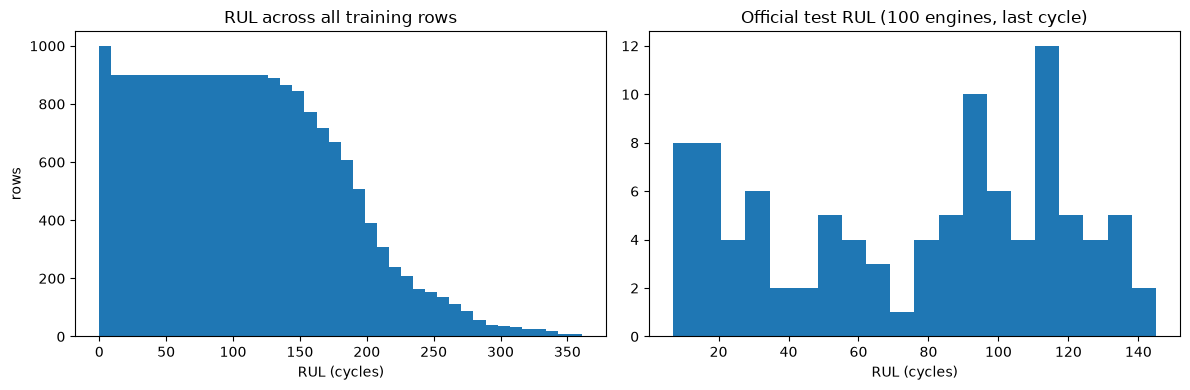

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train["RUL"], bins=40)
axes[0].set_title("RUL across all training rows")
axes[0].set_xlabel("RUL (cycles)")
axes[0].set_ylabel("rows")

axes[1].hist(rul_test["RUL"], bins=20)
axes[1].set_title("Official test RUL (100 engines, last cycle)")
axes[1].set_xlabel("RUL (cycles)")
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

dropped_constant = constant_cols
dropped_weak = ["setting_1", "setting_2", "sensor_6"]
feature_sensors = [c for c in sensor_names if c not in dropped_constant + dropped_weak]
print(len(feature_sensors), "sensors kept:", feature_sensors)

engine_ids = train["unit"].unique()
train_ids, val_ids = train_test_split(engine_ids, test_size=0.2, random_state=42)

print("train engines:", len(train_ids), "| val engines:", len(val_ids))
print("overlap:", set(train_ids) & set(val_ids))

train_part = train[train["unit"].isin(train_ids)].copy()
val_part = train[train["unit"].isin(val_ids)].copy()
print(train_part.shape, val_part.shape)

14 sensors kept: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
train engines: 80 | val engines: 20
overlap: set()
(16561, 27) (4070, 27)


In [8]:
import json

PROC_DIR.mkdir(parents=True, exist_ok=True)

train[["unit", "cycle"] + feature_sensors + ["RUL"]].to_csv(PROC_DIR / "train_with_rul.csv", index=False)

config = {
    "feature_sensors": feature_sensors,
    "dropped_constant": dropped_constant,
    "dropped_weak": dropped_weak,
    "train_engine_ids": sorted(int(i) for i in train_ids),
    "val_engine_ids": sorted(int(i) for i in val_ids),
    "split_random_state": 42,
}
with open(PROC_DIR / "preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("saved:", sorted(p.name for p in PROC_DIR.glob("*")))

saved: ['preprocessing_config.json', 'train_with_rul.csv']
